In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch
import sys
sys.path.insert(0, "../src")   # shared grid + map helpers live in src/grid.py
from grid import (LON_MIN, LON_MAX, LAT_MIN, LAT_MAX, RES, lon_edges, lat_edges,
                  lon_c, lat_c, nx, ny, cell_index, style_map, proj)

In [2]:
DATA_DIR = Path("../data")      # data, tables, results (parquet, npz, csv, json)
FIG_DIR  = Path("../figures")   # all figures (png)

# Each notebook writes to its own subfolder; inputs come from earlier notebooks' folders
OUT_DIR = DATA_DIR / "02_sampling_characterisation"
FIG_OUT = FIG_DIR / "02_sampling_characterisation"
DIR_01  = DATA_DIR / "01_data_prep_roni_gdp"          # kuroshio_obs_clean, roni_phase
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_OUT.mkdir(parents=True, exist_ok=True)

In [3]:
# Cleaned, RONI-tagged Kuroshio observations (01_data_prep_roni_gdp)
df = pd.read_parquet(DIR_01 / "kuroshio_obs_clean.parquet")

# Velocity analysis uses drogued drifters only (flag cross-checked against drogue loss date)
df_drogued = df[df["drogued"]].copy()

# Input check: notebook 01 already drops drogued hours with a missing velocity component
assert len(df_drogued) == 2_135_791 and df_drogued["id"].nunique() == 1_177
assert df_drogued[["ve", "vn"]].notna().all().all()

print(f"{len(df):,} obs total | {len(df_drogued):,} drogued from {df_drogued['id'].nunique():,} drifters")

summary = {"drogued_obs":      int(len(df_drogued)),
           "drogued_drifters": int(df_drogued["id"].nunique())}

4,623,446 obs total | 2,135,791 drogued from 1,177 drifters


### Sampling by ENSO phase

In [4]:
# --- How much data each ENSO phase has ---
def phase_summary(d, value_col):
    s = d.groupby("enso").agg(n_obs=(value_col, "count"),     # non-missing values
                              n_drifters=("id", "nunique"))   # distinct drifters
    s["share_obs"] = (s["n_obs"] / s["n_obs"].sum()).round(3)
    return s

phase_obs = {"vel": phase_summary(df_drogued, "ve"), "sst": phase_summary(df, "sst")}
print("Velocity (drogued):\n", phase_obs["vel"], "\n")
print("SST (all drifters):\n", phase_obs["sst"])

pd.concat([t.add_prefix(f"{k}_") for k, t in phase_obs.items()], axis=1).to_csv(OUT_DIR / "phase_obs_support.csv")

Velocity (drogued):
            n_obs  n_drifters  share_obs
enso                                   
El Niño   252229         212      0.118
La Niña   836252         501      0.392
Neutral  1047310         743      0.490 

SST (all drifters):
            n_obs  n_drifters  share_obs
enso                                   
El Niño   725198         381      0.165
La Niña  1677973         778      0.382
Neutral  1991911        1038      0.453


### Spatial support per 1 degree cell

In [5]:
# Grid (bounds, edges, centres, nx/ny), cell_index() and style_map() come from src/grid.py

def cell_support(d, value_col):
    """Return 2-D arrays (lat x lon) of observation counts and distinct-drifter counts."""
    d = d[d[value_col].notna()]                        # only rows with a valid value
    iy, ix = cell_index(d)
    g = (pd.DataFrame({"iy": iy, "ix": ix, "id": d["id"].values})
           .groupby(["iy", "ix"])
           .agg(n_obs=("id", "size"), n_drifters=("id", "nunique")))
    # Fill empty grids, then drop the counts into their cells
    n_obs = np.zeros((ny, nx)); n_dr = np.zeros((ny, nx))
    iy_idx, ix_idx = g.index.get_level_values("iy"), g.index.get_level_values("ix")
    n_obs[iy_idx, ix_idx] = g["n_obs"].values
    n_dr[iy_idx, ix_idx] = g["n_drifters"].values
    return n_obs, n_dr

THRESHOLDS = (5, 10, 20)

def support_stats(n_dr, cells):
    """Median drifters per cell and share of cells reaching each threshold, over `cells`."""
    v = n_dr[cells]
    return {"median_drifters": float(np.median(v)),
            **{f"share_ge{k}": round(float((v >= k).mean()), 4) for k in THRESHOLDS}}

def show(table):
    """Print a table with share columns as percentages (saved CSVs keep the numbers)."""
    out = table.copy()
    for c in out.columns:
        if c.startswith("share"):
            out[c] = out[c].map("{:.0%}".format)
    print(out.to_string())

In [6]:
phases = ["All", "Neutral", "La Niña", "El Niño"]
support_vel, support_sst = {}, {}
for p in phases:
    sub_dro = df_drogued if p == "All" else df_drogued[df_drogued["enso"] == p]
    sub_all = df if p == "All" else df[df["enso"] == p]
    support_vel[p] = cell_support(sub_dro, "ve")       # (n_obs, n_drifters), drogued only
    support_sst[p] = cell_support(sub_all, "sst")      # (n_obs, n_drifters), all drifters

# One definition used everywhere: ocean cells = at least one drogued velocity observation
ocean = support_vel["All"][1] > 0
sst_cells = support_sst["All"][1] > 0                  # cells with any valid SST

summary["n_ocean_cells_vel"] = int(ocean.sum())
summary["n_sst_cells"]       = int(sst_cells.sum())
print(f"ocean cells (velocity): {ocean.sum()} | SST cells: {sst_cells.sum()} | grid: {nx * ny}")

ocean cells (velocity): 595 | SST cells: 618 | grid: 750


### Effect of the drogue policy on velocity coverage

                hours  median_drifters share_ge5 share_ge10 share_ge20
drifters                                                              
all drifters  4623446             76.0       97%        94%        89%
drogued only  2135791             31.0       94%        90%        75%
share_hours_kept: 46.2%
share_drifters_kept: 76.9%
share_cells_kept: 95.7%


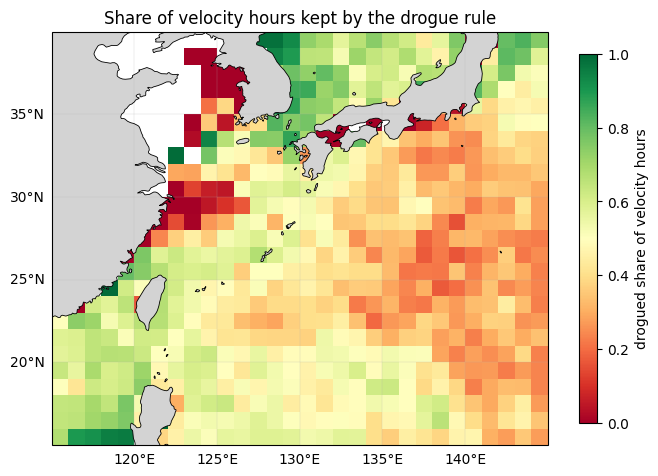

In [7]:
# Velocity support with all drifters vs drogued only (both over the same ocean cells)
nobs_all, ndr_all = cell_support(df, "ve")          # every drifter, any drogue state
nobs_dro, ndr_dro = support_vel["All"]              # drogued only (computed above)

policy = pd.DataFrame({
    "all drifters": {"hours": nobs_all.sum(), **support_stats(ndr_all, ocean)},
    "drogued only": {"hours": nobs_dro.sum(), **support_stats(ndr_dro, ocean)},
}).T
policy["hours"] = policy["hours"].astype(int)
policy.index.name = "drifters"
show(policy)
policy.to_csv(OUT_DIR / "drogue_policy_support.csv")

# --- Cost of the drogue rule ---
any_vel = ndr_all > 0                               # cells with velocity data from any drifter
drogue_cost = {
    "share_hours_kept":    nobs_dro.sum() / nobs_all.sum(),
    "share_drifters_kept": df_drogued["id"].nunique() / df.loc[df["ve"].notna(), "id"].nunique(),
    "share_cells_kept":    ocean.sum() / any_vel.sum(),
}
drogue_cost = {k: round(float(v), 4) for k, v in drogue_cost.items()}
for k, v in drogue_cost.items():
    print(f"{k}: {v:.1%}")
pd.Series(drogue_cost, name="value").to_csv(OUT_DIR / "drogue_cost.csv", index_label="metric")
summary["drogue_cost"] = drogue_cost

# Where is coverage lost? Share of each cell's velocity hours kept by the rule
kept = np.where(any_vel, nobs_dro / np.where(any_vel, nobs_all, 1), np.nan)

fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={"projection": proj})
im = ax.pcolormesh(lon_edges, lat_edges, kept, cmap="RdYlGn", vmin=0, vmax=1, transform=proj)
fig.colorbar(im, ax=ax, label="drogued share of velocity hours", shrink=0.8)
style_map(ax, "Share of velocity hours kept by the drogue rule")
fig.savefig(FIG_OUT / "drogue_share_map.png", dpi=300, bbox_inches="tight")
plt.show()

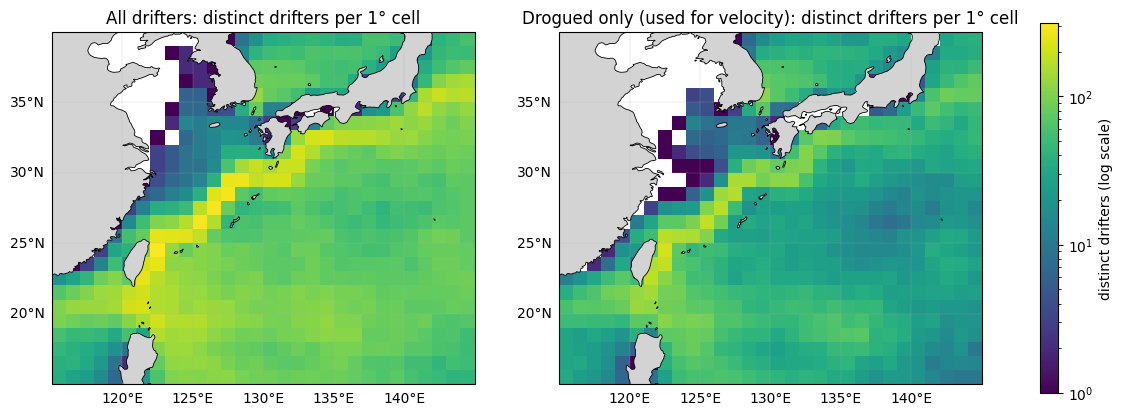

In [8]:
# Velocity support before and after the drogue rule (shared log colour scale)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), subplot_kw={"projection": proj})
norm = LogNorm(vmin=1, vmax=ndr_all.max())

for ax, n_dr, title in [(axes[0], ndr_all, "All drifters"),
                        (axes[1], ndr_dro, "Drogued only (used for velocity)")]:
    im = ax.pcolormesh(lon_edges, lat_edges, np.where(n_dr > 0, n_dr, np.nan),
                       norm=norm, cmap="viridis", transform=proj)
    style_map(ax, f"{title}: distinct drifters per {RES:g}° cell")

fig.colorbar(im, ax=axes, label="distinct drifters (log scale)", shrink=0.8)
fig.savefig(FIG_OUT / "drifters_per_cell_all_vs_drogued.png", dpi=300, bbox_inches="tight")
plt.show()

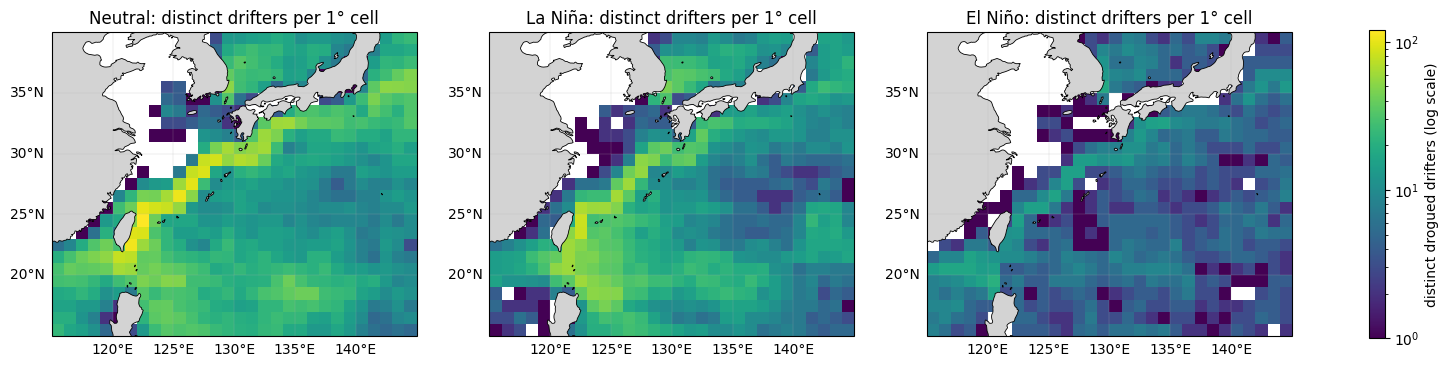

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5), subplot_kw={"projection": proj})
norm = LogNorm(vmin=1, vmax=support_vel["Neutral"][1].max())

for ax, p in zip(axes, phases[1:]):                    # Neutral, La Niña, El Niño
    n_dr = support_vel[p][1]
    im = ax.pcolormesh(lon_edges, lat_edges,
                       np.where(n_dr > 0, n_dr, np.nan),
                       norm=norm, cmap="viridis", transform=proj)
    style_map(ax, f"{p}: distinct drifters per {RES:g}° cell")

fig.colorbar(im, ax=axes, label="distinct drogued drifters (log scale)", shrink=0.8)
fig.savefig(FIG_OUT / "drifters_per_cell_by_phase.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
# Velocity support per ENSO phase, over ocean cells (>= 1 drogued velocity observation)
support_vel_tbl = pd.DataFrame({p: support_stats(support_vel[p][1], ocean) for p in phases}).T
support_vel_tbl.index.name = "phase"
print("Velocity (drogued):"); show(support_vel_tbl)
support_vel_tbl.to_csv(OUT_DIR / "support_vel_by_phase.csv")
summary["support_vel_by_phase"] = support_vel_tbl.to_dict(orient="index")

Velocity (drogued):
         median_drifters share_ge5 share_ge10 share_ge20
phase                                                   
All                 31.0       94%        90%        75%
Neutral             16.0       91%        78%        40%
La Niña             11.0       80%        58%        24%
El Niño              4.0       43%         9%         0%


In [11]:
# SST support per ENSO phase, over SST cells (any valid SST)
support_sst_tbl = pd.DataFrame({p: support_stats(support_sst[p][1], sst_cells) for p in phases}).T
support_sst_tbl.index.name = "phase"
print("SST (all drifters):"); show(support_sst_tbl)
support_sst_tbl.to_csv(OUT_DIR / "support_sst_by_phase.csv")
summary["support_sst_by_phase"] = support_sst_tbl.to_dict(orient="index")

SST (all drifters):
         median_drifters share_ge5 share_ge10 share_ge20
phase                                                   
All                 70.0       93%        90%        85%
Neutral             34.0       90%        86%        80%
La Niña             27.0       86%        82%        70%
El Niño             12.0       83%        68%        16%


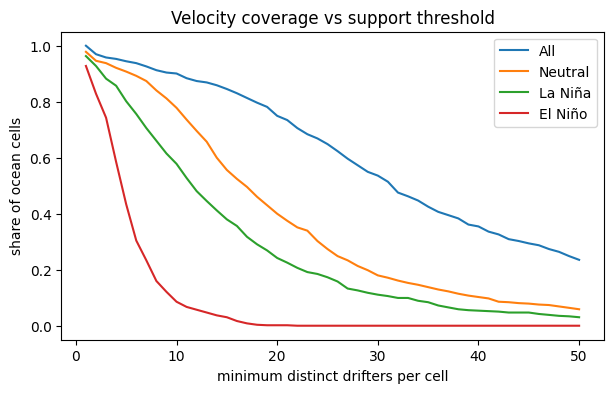

In [12]:
k = np.arange(1, 51)
coverage = pd.DataFrame({p: [(support_vel[p][1][ocean] >= i).mean() for i in k] for p in phases},
                        index=pd.Index(k, name="min_drifters")).round(4)
coverage.to_csv(OUT_DIR / "coverage_vs_threshold.csv")

fig, ax = plt.subplots(figsize=(7, 4))
for p in phases:
    ax.plot(k, coverage[p], label=p)
ax.set(xlabel="minimum distinct drifters per cell", ylabel="share of ocean cells",
       title="Velocity coverage vs support threshold")
ax.legend()
fig.savefig(FIG_OUT / "coverage_vs_threshold.png", dpi=300, bbox_inches="tight")
plt.show()

### Temporal Coverage

In [13]:
# --- Distinct ENSO events (contiguous runs of a phase in the RONI calendar) ---
roni_phase = pd.read_csv(DIR_01 / "roni_phase.csv", index_col=0, parse_dates=True)["enso"]
STUDY = ("1990-03", "2022-10")
rp = roni_phase[STUDY[0]:STUDY[1]]

runs = pd.DataFrame({"phase": rp.values, "month": rp.index,
                     "run": (rp != rp.shift()).cumsum().values})
events = (runs.groupby("run")
              .agg(phase=("phase", "first"), start=("month", "min"),
                   end=("month", "max"), n_months=("month", "size"))
              .query("phase != 'Neutral'")
              .reset_index(drop=True))
# Runs cut by the study window may be longer in the full RONI record
events["clipped"] = (events["start"] == rp.index[0]) | (events["end"] == rp.index[-1])

# Drogued velocity data inside each event
month_dro = df_drogued["time"].dt.to_period("M").dt.to_timestamp()
in_event = [(month_dro >= e.start) & (month_dro <= e.end) for e in events.itertuples()]
events["drogued_hours"]    = [int(m.sum()) for m in in_event]
events["drogued_drifters"] = [int(df_drogued.loc[m, "id"].nunique()) for m in in_event]

summary["enso_events"] = {}
for ph in ["El Niño", "La Niña"]:
    e = events[events["phase"] == ph]
    n_total, n_data = len(e), int((e["drogued_hours"] > 0).sum())
    summary["enso_events"][ph] = {"total": n_total, "with_drogued_data": n_data}
    print(f"{ph}: {n_total} events, {n_data} with drogued velocity data")
    for r in e.itertuples():
        print(f"  {r.start:%Y-%m} to {r.end:%Y-%m} ({r.n_months:2d} months): "
              f"{r.drogued_hours:7,} drogued hours, {r.drogued_drifters:3d} drifters"
              + ("  [clipped by study window]" if r.clipped else ""))

events.assign(start=events["start"].dt.strftime("%Y-%m"),
              end=events["end"].dt.strftime("%Y-%m")).to_csv(OUT_DIR / "enso_events.csv", index=False)

El Niño: 10 events, 7 with drogued velocity data
  1991-05 to 1992-07 (15 months):       0 drogued hours,   0 drifters
  1993-01 to 1993-06 ( 6 months):       0 drogued hours,   0 drifters
  1994-07 to 1995-03 ( 9 months):       0 drogued hours,   0 drifters
  1997-05 to 1998-04 (12 months):   1,835 drogued hours,   4 drifters
  2002-07 to 2003-01 ( 7 months):   5,216 drogued hours,   5 drifters
  2004-07 to 2005-01 ( 7 months):  22,747 drogued hours,  26 drifters
  2006-09 to 2007-01 ( 5 months):  23,581 drogued hours,  30 drifters
  2009-09 to 2010-03 ( 7 months):  62,264 drogued hours,  42 drifters
  2015-03 to 2016-04 (14 months): 104,619 drogued hours,  89 drifters
  2018-10 to 2019-04 ( 7 months):  31,967 drogued hours,  16 drifters
La Niña: 11 events, 10 with drogued velocity data
  1995-08 to 1996-03 ( 8 months):       0 drogued hours,   0 drifters
  1998-07 to 2000-06 (24 months):   2,688 drogued hours,   4 drifters
  2000-10 to 2001-03 ( 6 months):   1,366 drogued hours,   1 

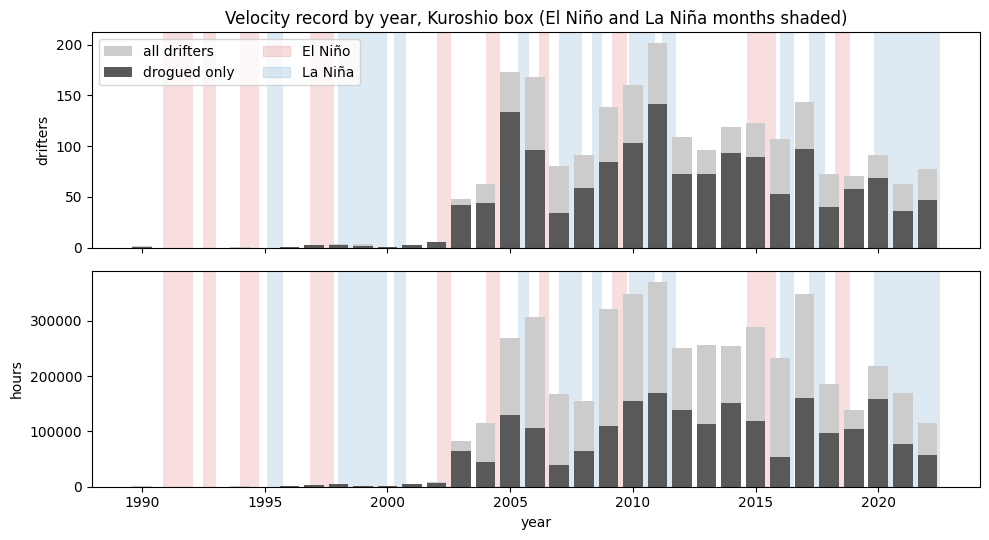

median year of drogued hours: 2013


In [14]:
# Velocity record of the whole box by year: all drifters vs drogued only
year_dro = df_drogued["time"].dt.year
year_all = df["time"].dt.year

history = pd.DataFrame({
    "drifters": df_drogued.groupby(year_dro)["id"].nunique(),
    "hours":    df_drogued.groupby(year_dro).size(),
})
history_all = pd.DataFrame({
    "drifters": df.groupby(year_all)["id"].nunique(),
    "hours":    df.groupby(year_all).size(),
})
(pd.concat([history_all.add_suffix("_all"), history.add_suffix("_drogued")], axis=1)
   .fillna(0).astype(int).rename_axis("year")
   .to_csv(OUT_DIR / "history_by_year.csv"))

# El Niño and La Niña months from the RONI calendar (not from drifter rows)
phase_colours = {"El Niño": "tab:red", "La Niña": "tab:blue"}
phase_months = {ph: roni_phase["1990":"2022"][lambda s: s == ph].index.to_period("M")
                for ph in phase_colours}

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
for ax, col in zip(axes, history.columns):
    for ph, colour in phase_colours.items():
        for m in phase_months[ph]:
            x0 = m.year + (m.month - 1) / 12 - 0.5      # -0.5 aligns with bars centred on each year
            ax.axvspan(x0, x0 + 1 / 12, color=colour, alpha=0.15, lw=0)
    ax.bar(history_all.index, history_all[col], color="0.8", label="all drifters")   # light, behind
    ax.bar(history.index, history[col], color="0.35", label="drogued only")         # dark, in front
    ax.set_ylabel(col)
handles, _ = axes[0].get_legend_handles_labels()
handles += [Patch(color=colour, alpha=0.15, label=ph) for ph, colour in phase_colours.items()]
axes[0].legend(handles=handles, loc="upper left", ncol=2)
axes[0].set_title("Velocity record by year, Kuroshio box (El Niño and La Niña months shaded)")
axes[-1].set_xlabel("year")
plt.tight_layout()
fig.savefig(FIG_OUT / "history_by_year.png", dpi=300, bbox_inches="tight")
plt.show()

summary["median_year_drogued_hours"] = float(year_dro.median())
print(f"median year of drogued hours: {year_dro.median():.0f}")

Distinct drifters (top) and hours (bottom) per year in the Kuroshio box, for all drifters (light) and drogued drifters used for velocity (dark). El Niño months are shaded (RONI ≥ +0.5 °C for ≥5 consecutive overlapping seasons). The box was barely sampled before 2002 (under 1% of drogued hours), so the 1990s El Niño events contribute almost no data: only 1997–98 has any (1,835 hours from 4 drifters). El Niño velocity estimates therefore rest on six events between 2002 and 2019, of which 2002–03 is itself thin (5 drifters). The drogue criterion removes proportionally more hours than drifters, because drifters typically stay long after losing their drogues. Hour counts are therefore a poor guide to support.

In [15]:
# Check: how unevenly do drifters contribute to each cell?
def cell_table(d, value_cols):
    """Per-cell support: hours, drifters, effective drifters, top contributor's share,
    typical hours per drifter visit, and distinct calendar years with data."""
    d = d.dropna(subset=value_cols)
    iy, ix = cell_index(d)
    tmp = pd.DataFrame({"iy": iy, "ix": ix, "id": d["id"].values, "year": d["time"].dt.year.values})
    hours = tmp.groupby(["iy", "ix", "id"]).size()                 # total hours per (cell, drifter)
    by_cell = hours.groupby(level=["iy", "ix"])
    t = pd.DataFrame({
        "n_obs":           by_cell.sum(),
        "n_drifters":      by_cell.size(),                                    # actual drifters
        "n_eff":           by_cell.sum() ** 2 / (hours ** 2).groupby(level=["iy", "ix"]).sum(),  # effective drifters
        "top_share":       by_cell.max() / by_cell.sum(),                     # share from biggest contributor
        "hours_per_visit": by_cell.median(),                                  # typical hours per drifter
        "n_years":         tmp.groupby(["iy", "ix"])["year"].nunique(),       # distinct years with data
    })
    t["eff_ratio"] = t["n_eff"] / t["n_drifters"]
    t = t.reset_index()
    t.insert(2, "lon", LON_MIN + (t["ix"] + 0.5) * RES)                       # cell centre
    t.insert(3, "lat", LAT_MIN + (t["iy"] + 0.5) * RES)
    return t

cell_vel = cell_table(df_drogued, ["ve", "vn"])
cell_sst = cell_table(df, ["sst"])
cell_vel.to_parquet(OUT_DIR / "cell_support_vel.parquet", index=False)
cell_sst.to_parquet(OUT_DIR / "cell_support_sst.parquet", index=False)

med_cols = ["n_obs", "n_drifters", "n_eff", "eff_ratio", "top_share", "hours_per_visit", "n_years"]
cell_medians = pd.DataFrame({"velocity": cell_vel[med_cols].median(), "sst": cell_sst[med_cols].median()})
print(cell_medians.round(2).to_string())
cell_medians.to_csv(OUT_DIR / "cell_support_medians.csv", index_label="statistic")
summary["cell_medians"] = {k: {s: round(float(v), 4) for s, v in col.items()}
                           for k, col in cell_medians.items()}

                 velocity      sst
n_obs             3221.00  7461.00
n_drifters          31.00    70.00
n_eff               16.20    35.63
eff_ratio            0.55     0.52
top_share            0.13     0.07
hours_per_visit     75.00    76.75
n_years             13.00    18.00


Drifter contributions within cells are uneven. A typical drifter remains in a 1° cell for about 75 hours, so its hourly records are strongly correlated. In the median cell, the largest single contributor supplies 13% of the hours, and the 31 drifters present are equivalent to about 16 equally contributing drifters (55%). Hourly observation counts therefore greatly overstate the independent information in each cell, which motivates estimating uncertainty by resampling whole drifters rather than individual observations.

In [16]:
# --- Key numbers for Section 3 (sampling) ---
summary["n_cells_grid"]    = int(nx * ny)                    # all cells in the box
summary["n_cells_any_vel"] = int(any_vel.sum())              # velocity from any drifter (drogued or not)
(OUT_DIR / "02_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "drogued_obs": 2135791,
  "drogued_drifters": 1177,
  "n_ocean_cells_vel": 595,
  "n_sst_cells": 618,
  "drogue_cost": {
    "share_hours_kept": 0.4619,
    "share_drifters_kept": 0.7688,
    "share_cells_kept": 0.9566
  },
  "support_vel_by_phase": {
    "All": {
      "median_drifters": 31.0,
      "share_ge5": 0.9445,
      "share_ge10": 0.9008,
      "share_ge20": 0.7496
    },
    "Neutral": {
      "median_drifters": 16.0,
      "share_ge5": 0.9076,
      "share_ge10": 0.7782,
      "share_ge20": 0.4
    },
    "La Niña": {
      "median_drifters": 11.0,
      "share_ge5": 0.8017,
      "share_ge10": 0.5782,
      "share_ge20": 0.242
    },
    "El Niño": {
      "median_drifters": 4.0,
      "share_ge5": 0.4336,
      "share_ge10": 0.0857,
      "share_ge20": 0.0017
    }
  },
  "support_sst_by_phase": {
    "All": {
      "median_drifters": 70.0,
      "share_ge5": 0.9337,
      "share_ge10": 0.8964,
      "share_ge20": 0.8528
    },
    "Neutral": {
      "median_drifters"